# Lab 14-09 · Memory Hierarchy and Caches

Companion to [chapter 14-09](../../chapters/14-09-memory-hierarchy-and-caches.md). The C kernels in `kernels.c` are compiled with clang and run on the course's RV32IM simulator; `cache.py` records their data accesses and replays them through cache models. Run the cells in order.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import cache
sys.path.insert(0, str(Path('../14-08-lab').resolve()))
import ooo

## Part 1 · Mapping

Split an address, then replay Example 14-09.2's nine accesses and watch the sets.

In [2]:
c = cache.Cache(32 * 1024, 64, 8)
tag, idx, off = c.split(0x12345678)
print(f'32 KB 8-way 64 B: {c.nsets} sets; 0x12345678 -> tag {tag:#x}, index {idx}, offset {off}')

ex2 = [(a, False) for a in (0x000, 0x040, 0x004, 0x080, 0x044, 0x008, 0x010, 0x050, 0x014)]
for assoc in (1, 2, 4):
    c = cache.Cache(64, 16, assoc)
    rows = []
    for a, st in ex2:
        hit = c.access(a, st)
        state = ' | '.join(' '.join(str(ln[0] * c.nsets + i) for ln in s) or '-' for i, s in enumerate(c.sets))
        rows.append(f'  block {a // 16}: {"H" if hit else "M"}   sets: {state}')
    print(f'{assoc}-way: {c.misses} misses'); print('\n'.join(rows))

32 KB 8-way 64 B: 64 sets; 0x12345678 -> tag 0x12345, index 25, offset 56
1-way: 9 misses
  block 0: M   sets: 0 | - | - | -
  block 4: M   sets: 4 | - | - | -
  block 0: M   sets: 0 | - | - | -
  block 8: M   sets: 8 | - | - | -
  block 4: M   sets: 4 | - | - | -
  block 0: M   sets: 0 | - | - | -
  block 1: M   sets: 0 | 1 | - | -
  block 5: M   sets: 0 | 5 | - | -
  block 1: M   sets: 0 | 1 | - | -
2-way: 7 misses
  block 0: M   sets: 0 | -
  block 4: M   sets: 0 4 | -
  block 0: H   sets: 4 0 | -
  block 8: M   sets: 0 8 | -
  block 4: M   sets: 8 4 | -
  block 0: M   sets: 4 0 | -
  block 1: M   sets: 4 0 | 1
  block 5: M   sets: 4 0 | 1 5
  block 1: H   sets: 4 0 | 5 1
4-way: 5 misses
  block 0: M   sets: 0
  block 4: M   sets: 0 4
  block 0: H   sets: 4 0
  block 8: M   sets: 4 0 8
  block 4: H   sets: 0 8 4
  block 0: H   sets: 8 4 0
  block 1: M   sets: 8 4 0 1
  block 5: M   sets: 4 0 1 5
  block 1: H   sets: 4 0 5 1


## Part 2 · The three Cs

Rows and columns of a 64 × 64 integer matrix.

In [3]:
rows, _ = cache.traverse('rows')
cols, _ = cache.traverse('cols')
for name, tr in (('rows', rows), ('columns', cols)):
    for size in (1024, 2048, 4096, 8192, 16384):
        print(f'{name:8s} {size // 1024:2d} KB direct-mapped:', cache.three_c(tr, size, 32, 1))
print()
for assoc in (1, 2, 4, 8, 16, 128):
    print(f'columns, 4 KB, {assoc:3d}-way:', cache.Cache(4096, 32, assoc).run(cols).misses, 'misses')

rows      1 KB direct-mapped: {'compulsory': 512, 'capacity': 0, 'conflict': 0, 'total': 512}
rows      2 KB direct-mapped: {'compulsory': 512, 'capacity': 0, 'conflict': 0, 'total': 512}
rows      4 KB direct-mapped: {'compulsory': 512, 'capacity': 0, 'conflict': 0, 'total': 512}
rows      8 KB direct-mapped: {'compulsory': 512, 'capacity': 0, 'conflict': 0, 'total': 512}
rows     16 KB direct-mapped: {'compulsory': 512, 'capacity': 0, 'conflict': 0, 'total': 512}
columns   1 KB direct-mapped: {'compulsory': 512, 'capacity': 3584, 'conflict': 0, 'total': 4096}
columns   2 KB direct-mapped: {'compulsory': 512, 'capacity': 0, 'conflict': 3584, 'total': 4096}
columns   4 KB direct-mapped: {'compulsory': 512, 'capacity': 0, 'conflict': 3584, 'total': 4096}
columns   8 KB direct-mapped: {'compulsory': 512, 'capacity': 0, 'conflict': 3584, 'total': 4096}
columns  16 KB direct-mapped: {'compulsory': 512, 'capacity': 0, 'conflict': 0, 'total': 512}

columns, 4 KB,   1-way: 4096 misses
columns

columns, 4 KB, 128-way: 512 misses


## Part 3 · Matrix multiply

**Predict first:** which tile size is best for a 2 KB cache? (Hint: a $t \times t$ tile of integers occupies $4t^2$ bytes.)

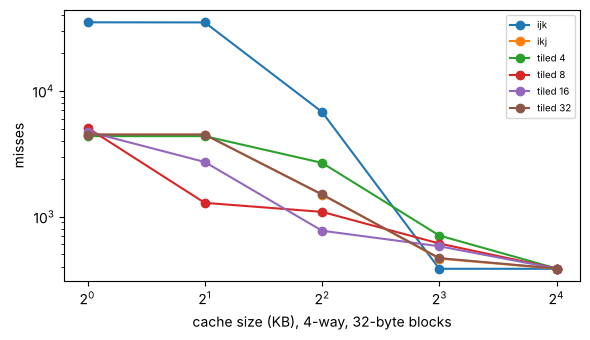

ijk       {'lru': 34952, 'fifo': 35000, 'random': 30271}
ikj       {'lru': 4480, 'fifo': 4720, 'random': 4403}


tiled 4   {'lru': 4356, 'fifo': 4988, 'random': 5084}
tiled 8   {'lru': 1284, 'fifo': 1600, 'random': 1981}


tiled 16  {'lru': 2714, 'fifo': 2502, 'random': 2572}
tiled 32  {'lru': 4484, 'fifo': 4724, 'random': 4468}


ijk block sizes (4 KB 4-way): {16: 7464, 32: 6788, 64: 5612, 128: 5304}
ikj block sizes (4 KB 4-way): {16: 2987, 32: 1495, 64: 749, 128: 376}


In [4]:
mm = {'ijk': cache.matmul('ijk')[0], 'ikj': cache.matmul('ikj')[0]}
for t in (4, 8, 16, 32):
    mm[f'tiled {t}'] = cache.matmul('tiled', t=t)[0]
sizes = [1024, 2048, 4096, 8192, 16384]
plt.figure(figsize=(6, 3.5))
for name, tr in mm.items():
    plt.plot([s // 1024 for s in sizes], [cache.Cache(s, 32, 4).run(tr).misses for s in sizes], marker='o', label=name)
plt.xscale('log', base=2); plt.yscale('log'); plt.xlabel('cache size (KB), 4-way, 32-byte blocks'); plt.ylabel('misses')
plt.legend(fontsize=7); plt.tight_layout(); plt.show()
for name, tr in mm.items():
    print(f'{name:9s}', {p: cache.Cache(2048, 32, 4, policy=p).run(tr).misses for p in ('lru', 'fifo', 'random')})
for name in ('ijk', 'ikj'):
    print(name, 'block sizes (4 KB 4-way):', {b: cache.Cache(4096, b, 4).run(mm[name]).misses for b in (16, 32, 64, 128)})

## Part 4 · Writes

In [5]:
for name, (tr, _) in (('histogram', cache.histogram()), ('copy', cache.copy())):
    size, assoc = (1024, 2) if name == 'histogram' else (4096, 2)
    for wb in (True, False):
        for wa in (True, False):
            c = cache.Cache(size, 32, assoc, write_back=wb, write_allocate=wa).run(tr)
            c.flush()
            print(f'{name:9s} {"write-back   " if wb else "write-through"} {"allocate   " if wa else "no-allocate"}: {c.misses:4d} misses, traffic {c.traffic()}')

histogram write-back    allocate   :   34 misses, traffic {'read': 1088, 'write': 64}
histogram write-back    no-allocate:   34 misses, traffic {'read': 1088, 'write': 64}
histogram write-through allocate   :   34 misses, traffic {'read': 1088, 'write': 4000}
histogram write-through no-allocate:   34 misses, traffic {'read': 1088, 'write': 4000}
copy      write-back    allocate   :   64 misses, traffic {'read': 2048, 'write': 1024}
copy      write-back    no-allocate:  288 misses, traffic {'read': 1024, 'write': 1024}
copy      write-through allocate   :   64 misses, traffic {'read': 2048, 'write': 1024}
copy      write-through no-allocate:  288 misses, traffic {'read': 1024, 'write': 1024}


## Part 5 · Prefetching

**Predict first:** how many misses remain in the row and column traversals with a next-line prefetcher?

In [6]:
lst, _ = cache.linked_list()
for name, tr in (('rows', rows), ('columns', cols), ('list', lst)):
    off = cache.Cache(4096, 32, 4).run(tr)
    on = cache.Cache(4096, 32, 4, prefetch=True).run(tr)
    print(f'{name:8s} misses {off.misses:5d} -> {on.misses:5d}; prefetches {on.prefetches:5d}; hits {off.hits:5d} -> {on.hits:5d}')

rows     misses   512 ->     1; prefetches   512; hits  3584 ->  4095
columns  misses  4096 ->  4096; prefetches  4096; hits     0 ->     0
list     misses   256 ->   256; prefetches   256; hits     0 ->     0


## Part 6 · Which misses can an out-of-order core hide?

Each load's latency comes from a 4 KB 4-way cache with 64-byte blocks (hit 3 cycles, miss 100) and is fed into 14-08's model.

In [7]:
ARR = ooo.HEAD + '''    li a0, 0x2000
    li a1, 256
    li t0, 0
1:  lw   t1, 0(a0)
    add  t0, t0, t1
    addi a0, a0, 4
    addi a1, a1, -1
    bnez a1, 1b
    ebreak
'''
LST = ooo.HEAD + '''    li a0, 0x2000
    li t0, 0
1:  lw   a0, 0(a0)
    addi t0, t0, 1
    bnez a0, 1b
    ebreak
'''
lst_data = {}
for i in range(256):
    lst_data.update(ooo.words([0x2000 + 64 * (i + 1) if i < 255 else 0], 0x2000 + 64 * i))

def with_cache(src, data):
    tr, _ = ooo.dyn_trace({'x.s': src}, data)
    c = cache.Cache(4096, 64, 4)
    lat = {i: 100 for i, t in enumerate(tr) if t[1] == 'load' and not c.access(t[5])}
    return tr, lat

for name, (tr, lat) in (('array', with_cache(ARR, ooo.words(list(range(1, 257))))), ('list', with_cache(LST, lst_data))):
    row = {rob: ooo.schedule(tr, width=4, rob=rob, lat_of=lat)['cycles'] for rob in (16, 32, 64, 128, 256)}
    print(f'{name:5s}: {len(lat)} misses; in order {ooo.schedule(tr, width=1, rob=16, in_order=True, lat_of=lat)["cycles"]} cycles; 4-wide by window: {row}')

array: 16 misses; in order 3349 cycles; 4-wide by window: {16: 1941, 32: 1833, 64: 1713, 128: 913, 256: 537}


list : 256 misses; in order 25861 cycles; 4-wide by window: {16: 25604, 32: 25604, 64: 25604, 128: 25604, 256: 25604}
